# Gradient Descent

## The Idea Behind Gradient Descent

Let's take a simple function that takes a vector and gives back one number: the sum of squares.

$$f(v) = v_1^2 + v_2^2 + \dots + v_n^2$$

Example: f([1, 2, 3]) = 1 + 4 + 9 = 14

It is smallest (= 0) when v = [0, 0, …, 0]. We already know that, but let's pretend we don't and let gradient descent find it.

In [2]:
import math
from functools import partial
import numpy as np
import matplotlib.pyplot as plt

In [3]:
# Sum of the squared elements of v

# Plain Python
def sum_of_squares(v):
    return sum(v_i ** 2 for v_i in v)

print("Python:", sum_of_squares([1, 2, 3]))

# NumPy: no loop needed, works on the whole array at once
def sum_of_squares_np(v):
    return np.sum(v ** 2)

print("NumPy: ", sum_of_squares_np(np.array([1, 2, 3])))

Python: 14
NumPy:  14


### gradient:
The gradient is a vector that points in the direction where the function increases fastest (the "uphill" direction).

- To maximize a function $\to$ step with the gradient (go uphill)
- To minimize a function $\to$ step against the gradient (go downhill)

This is **gradient descent**

For sum of squares, the gradient is simply 2 × each element: gradient of [1, 2, 3] = [2, 4, 6].

Gradient descent on the simplest case, f(x) = $x^2$, starting at x = 8:

In [4]:
# Vector substract, multiplication and distance

def vector_subtract(v, w):
    return [v_i - w_i for v_i, w_i in zip(v, w)]

def scalar_multiply(c, v):
    return [c * v_i for v_i in v]

def distance(v, w):
    return math.sqrt(sum((v_i - w_i) ** 2 for v_i, w_i in zip(v, w)))

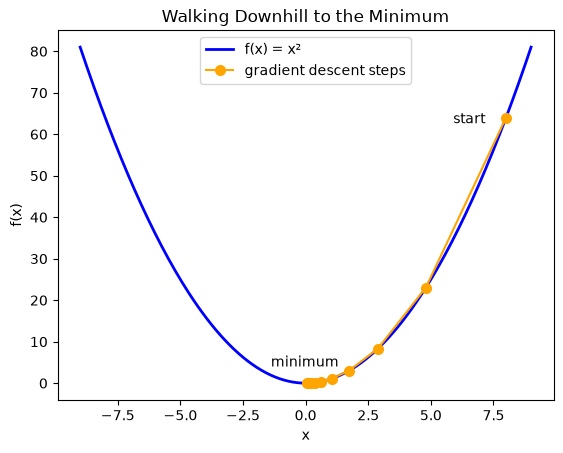

x after each step: [8.0, 4.8, 2.88, 1.728, 1.037, 0.622, 0.373, 0.224, 0.134, 0.081, 0.048]


In [5]:
f = lambda x: x ** 2
f_slope = lambda x: 2 * x              # derivative (slope) of x²

x = 8.0
path = [x]
for _ in range(10):
    x = x - 0.2 * f_slope(x)          # step AGAINST the slope
    path.append(x)

xs = np.linspace(-9, 9, 200)
plt.plot(xs, xs ** 2, color="blue", linewidth=2, label="f(x) = x²")
plt.plot(path, [f(p) for p in path], "o-", color="orange", markersize=7, label="gradient descent steps")
plt.annotate("start", (path[0], f(path[0])), textcoords="offset points", xytext=(-38, -4))
plt.annotate("minimum", (0, 0), textcoords="offset points", xytext=(-25, 12))
plt.title("Walking Downhill to the Minimum")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.legend()
plt.show()

print("x after each step:", [round(p, 3) for p in path])

## Estimating the Gradient

For a function of one variable, the derivative at x tells us how fast f(x) changes when x changes a tiny bit. It is the slope of the curve at that point.

We can estimate it using the difference quotient: move a tiny amount h and measure the change.

$$\text{slope} \approx \frac{f(x + h) - f(x)}{h} \quad \text{(for a very small } h\text{)}$$

For f(x) = $x^2$, we know the exact derivative is 2x. Let's check that our estimate matches.

x = 3 -> actual: 6 | estimate: 6.0
NumPy estimates for x = -2..2: [-4. -2.  0.  2.  4.]


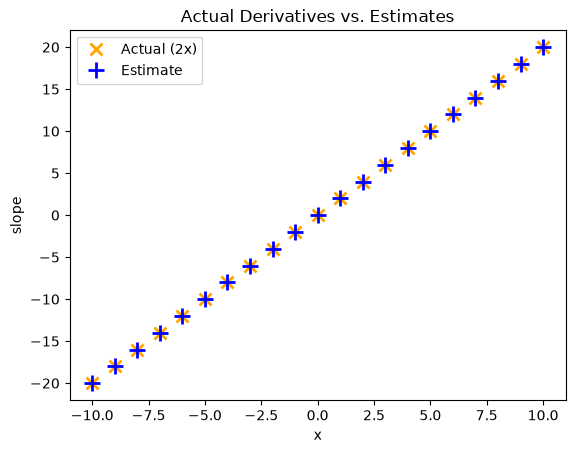

In [8]:
def square(x):
    return x ** 2

def derivative(x):
    return 2 * x

def difference_quotient(f, x, h):
    return (f(x + h) - f(x)) / h

derivative_estimate = partial(difference_quotient, square, h=0.00001)

# Plain Python
x_values = range(-10, 11)
actual = [derivative(x) for x in x_values]
estimate = [derivative_estimate(x) for x in x_values]  
print("x = 3 -> actual:", derivative(3), "| estimate:", round(derivative_estimate(3), 4))

# NumPy: the same formula works on a whole array in ONE line
x_arr = np.arange(-10, 11)
h = 0.00001
estimate_np = (square(x_arr + h) - square(x_arr)) / h
print("NumPy estimates for x = -2..2:", np.round(estimate_np[8:13], 4))

plt.plot(x_values, actual, "x", color='orange', markersize=9, markeredgewidth=2, label="Actual (2x)")
plt.plot(x_values, estimate, "+", color='blue', markersize=12, markeredgewidth=2, label="Estimate")
plt.title("Actual Derivatives vs. Estimates")
plt.xlabel("x")
plt.ylabel("slope")
plt.legend(loc="upper left")
plt.show()

In [10]:
# Plain Python
def partial_difference_quotient(f, v, i, h):
    """Estimate the i-th partial derivative of f at v"""
    w = [v_j + (h if j == i else 0)          # add h to ONLY the i-th element
         for j, v_j in enumerate(v)]
    return (f(w) - f(v)) / h

def estimate_gradient(f, v, h=0.00001):
    return [partial_difference_quotient(f, v, i, h) for i, _ in enumerate(v)]

print("Python estimate:", [round(g, 4) for g in estimate_gradient(sum_of_squares, [1, 2, 3])])

# NumPy: np.eye(n) gives n rows, each with a single 1, so we can nudge every element at once
def estimate_gradient_np(f, v, h=0.00001):
    v = np.asarray(v, dtype=float)
    nudges = np.eye(len(v)) * h                       # row i = add h to element i only
    return np.array([(f(v + nudge) - f(v)) / h for nudge in nudges])

print("NumPy estimate: ", np.round(estimate_gradient_np(sum_of_squares_np, [1, 2, 3]), 4))

Python estimate: [2.0, 4.0, 6.0]
NumPy estimate:  [2. 4. 6.]
